# LLM + Fuzzy TOPSIS — reproduction of the results

This notebook only reads `results/` (produced by `python -m scripts.run_experiments`) and
re-runs the cheap, LLM-free computations (TOPSIS, sensitivity). Re-running the experiment
script itself is also free once the LLM cache `.cache/llm_cache.sqlite` exists.

In [1]:
import sys, json
from pathlib import Path
ROOT = Path.cwd().parent if Path.cwd().name == 'notebooks' else Path.cwd()
sys.path.insert(0, str(ROOT))
import numpy as np, pandas as pd, matplotlib.pyplot as plt
pd.set_option('display.precision', 3); pd.set_option('display.width', 200)
RES = ROOT / 'results'; FIG = RES / 'figures'; FIG.mkdir(parents=True, exist_ok=True)
MODELS = sorted(p.name for p in RES.iterdir() if p.is_dir() and (p / 'synthetic_metrics.csv').exists())
MAIN = 'qwen3.5_4b' if 'qwen3.5_4b' in MODELS else (MODELS[-1] if MODELS else None)
print('result folders:', MODELS, '| main:', MAIN)

result folders: ['qwen3.5_0.8b', 'qwen3.5_4b'] | main: qwen3.5_4b


## 1. Validation of the from-scratch Fuzzy TOPSIS on Chen (2000)

In [2]:
cc = pd.read_csv(RES / 'crosscheck' / 'crosscheck_chen2000.csv'); display(cc)
p = RES / 'crosscheck' / 'crosscheck_skfuzzy.txt'
print(p.read_text() if p.exists() else 'scikit-fuzzy check not run')

,input,alternative,paper_d_plus,recomputed_from_table7_d_plus,ours_d_plus,paper_d_minus,ours_d_minus,paper_CC,ours_CC_chen,ours_rank,ours_CC_componentwise,pyDecision_CC,abs_diff_ours_componentwise_vs_pyDecision
0,table4_ratings,A1,2.10,1.94,1.946,3.45,3.429,0.62,0.638,3,0.128,0.128,0.000e+00
1,table4_ratings,A2,1.24,1.26,1.259,4.13,4.106,0.77,0.765,1,1.000,1.000,0.000e+00
2,table4_ratings,A3,1.59,1.59,1.602,3.85,3.771,0.71,0.702,2,0.539,0.539,0.000e+00
3,printed_table5,A1,2.10,1.94,1.942,3.45,3.450,0.62,0.640,3,0.113,0.113,0.000e+00
4,printed_table5,A2,1.24,1.26,1.262,4.13,4.123,0.77,0.766,1,1.000,1.000,0.000e+00
5,printed_table5,A3,1.59,1.59,1.591,3.85,3.841,0.71,0.707,2,0.563,0.563,1.110e-16


max |skfuzzy.trimf - ours| over 12 TFNs (Chen 7-term + our 5-term scales), 1001 points: 0.00e+00
max |skfuzzy centroid - (l+m+u)/3| over our 5-term scale (numeric integration): 2.22e-16
Note: scikit-fuzzy has no TOPSIS; it is used only to validate membership functions and centroids.



## 2. Synthetic benchmark — agreement with the ground-truth ranking

,job,spearman,kendall_tau,top1,top3_overlap,top5_overlap
method,,,,,,
fuzzy_topsis,J1,0.751,0.575,1.0,0.667,0.6
crisp_topsis,J1,0.772,0.596,1.0,0.667,0.6
weighted_sum,J1,0.792,0.628,1.0,1.000,0.6
tfidf_cosine,J1,0.756,0.606,1.0,0.667,0.6
fuzzy_topsis_llm_weights,J1,0.685,0.511,1.0,0.667,0.6
fuzzy_topsis_minmax_ideal,J1,0.778,0.606,1.0,0.667,0.6
oracle_terms_fuzzy_topsis,J1,0.938,0.818,0.0,1.000,1.0
fuzzy_topsis,J2,0.780,0.628,1.0,0.667,1.0
crisp_topsis,J2,0.806,0.649,1.0,0.667,1.0


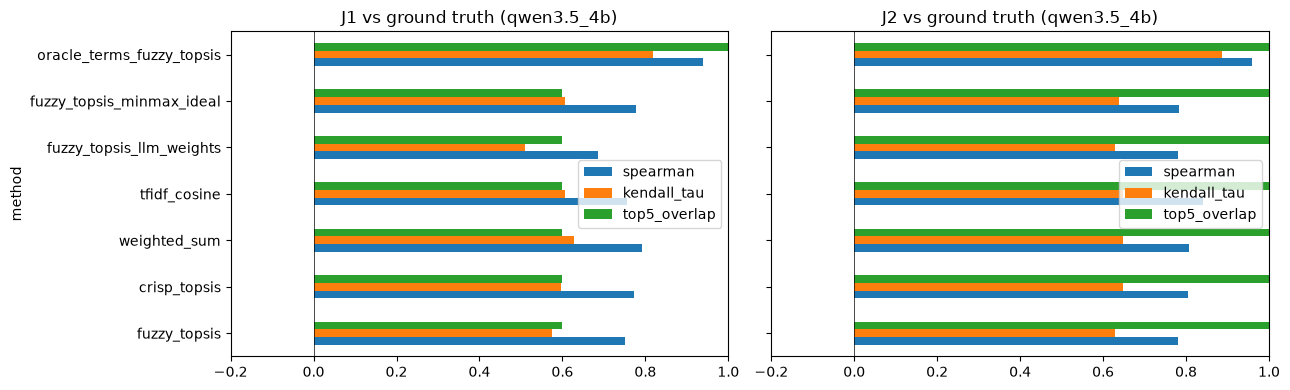

In [3]:
m = pd.read_csv(RES / MAIN / 'synthetic_metrics.csv', index_col=0); display(m)
fig, axes = plt.subplots(1, 2, figsize=(13, 4), sharey=True)
for ax, (job, g) in zip(axes, m.groupby('job')):
    g[['spearman', 'kendall_tau', 'top5_overlap']].plot.barh(ax=ax)
    ax.set_title(f'{job} vs ground truth ({MAIN})'); ax.set_xlim(-0.2, 1); ax.axvline(0, c='k', lw=.5)
plt.tight_layout(); plt.savefig(FIG / 'metrics_by_method.png', dpi=150); plt.show()

J1


,rank,candidate_id,archetype,CC,gt_rank,gt_score,C1_term,C2_term,C3_term,C4_term,C5_term,C6_term
0,1,S03,data_science,0.421,1,0.667,High,Very High,Low,Medium,High,Very High
1,2,S09,ml_engineering,0.350,3,0.608,High,Very Low,High,Very Low,High,Very High
2,3,S02,data_science,0.348,9,0.398,Medium,Very Low,Medium,High,Medium,Very High
3,4,S04,data_science,0.339,2,0.632,High,Very High,Low,Very Low,High,Low
4,5,S13,backend,0.320,7,0.454,Very Low,Low,High,Medium,High,Very High
5,6,S01,data_science,0.318,6,0.484,High,Very High,Low,Very Low,Medium,Low
6,7,S16,devops,0.293,13,0.292,Very Low,Very Low,High,Very Low,Medium,Very Low
7,8,S17,devops,0.263,11,0.354,Low,Very Low,Low,Low,Medium,Very High
8,9,S07,data_analysis,0.247,5,0.516,Low,Low,Low,Very Low,Medium,Low
9,10,S05,data_analysis,0.245,4,0.546,Low,Very Low,Very High,Very Low,Low,Low


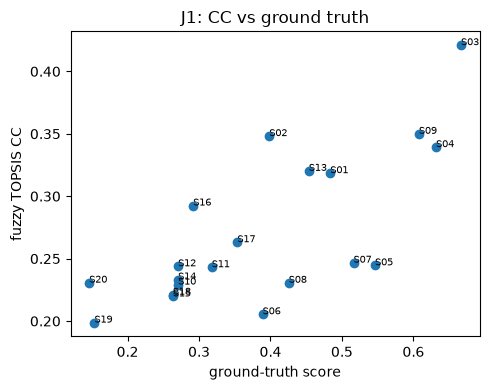

J2


,rank,candidate_id,archetype,CC,gt_rank,gt_score,C1_term,C2_term,C3_term,C4_term,C5_term,C6_term
0,1,S13,backend,0.450,1,0.707,High,High,High,High,Medium,High
1,2,S11,backend,0.437,3,0.670,Very High,High,High,Medium,Medium,Very High
2,3,S10,backend,0.414,4,0.633,Very High,Very Low,Medium,High,Medium,High
3,4,S12,backend,0.407,2,0.689,Medium,Medium,High,Medium,High,Very High
4,5,S09,ml_engineering,0.346,5,0.488,Medium,Very Low,High,Very Low,High,Very High
5,6,S16,devops,0.333,7,0.439,Very Low,Very Low,Very High,Medium,High,Very High
6,7,S17,devops,0.328,6,0.461,Low,Very Low,Medium,Medium,Medium,Very High
7,8,S08,ml_engineering,0.302,9,0.324,Very Low,Low,High,Very Low,Medium,High
8,9,S05,data_analysis,0.277,17,0.255,Very Low,Low,High,Very Low,Medium,High
9,10,S04,data_science,0.274,11,0.298,Very Low,Low,Medium,Very Low,High,Very High


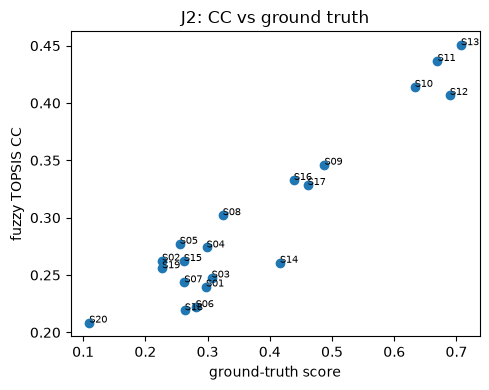

In [4]:
for job in ['J1', 'J2']:
    t = pd.read_csv(RES / MAIN / f'ranking_{job}.csv')
    cols = ['rank', 'candidate_id', 'archetype', 'CC', 'gt_rank', 'gt_score'] + [f'C{i}_term' for i in range(1, 7)]
    print(job); display(t[cols].head(10))
    plt.figure(figsize=(5, 4)); plt.scatter(t.gt_score, t.CC)
    for _, r in t.iterrows(): plt.annotate(r.candidate_id, (r.gt_score, r.CC), fontsize=7)
    plt.xlabel('ground-truth score'); plt.ylabel('fuzzy TOPSIS CC'); plt.title(f'{job}: CC vs ground truth')
    plt.tight_layout(); plt.savefig(FIG / f'cc_vs_gt_{job}.png', dpi=150); plt.show()

## 3. Extraction quality and per-criterion rating quality

In [5]:
display(pd.read_csv(RES / MAIN / 'extraction_accuracy_mean.csv', index_col=0))
display(pd.read_csv(RES / MAIN / 'rating_quality.csv').pivot(index='criterion', columns='job'))

,skill_recall,skill_precision,years_true,years_pred,years_abs_err,degree_level_ok,language_recall,cert_recall
mean,0.785,0.8,6.35,3.95,2.4,0.95,0.95,0.833


spearman               mae        evidence_verified_rate      
job             J1         J2     J1     J2                     J1    J2
criterion                                                               
C1           0.897  8.203e-01  0.120  0.105                   0.80  0.90
C2           0.278  5.438e-01  0.331  0.189                   0.95  0.85
C3           0.830  9.207e-01  0.124  0.103                   1.00  1.00
C4           0.624  9.102e-01  0.161  0.114                   0.95  1.00
C5           0.465 -7.994e-04  0.181  0.246                   0.90  0.80
C6           0.888  3.932e-01  0.217  0.214                   0.95  1.00

## 4. Ablations (computed from stored LLM answers: no extra call)

In [6]:
a = pd.read_csv(RES / MAIN / 'ablation.csv'); display(a)
s = RES / MAIN / 'stability.csv'
if s.exists(): display(pd.read_csv(s))

,job,grounding_policy,runs,aggregation,spearman,kendall_tau
0,J1,flag,1,mean,0.847,0.702
1,J1,flag,3,minmeanmax,0.714,0.543
2,J1,flag,3,mean,0.801,0.628
3,J1,downgrade,1,mean,0.788,0.635
4,J1,downgrade,3,minmeanmax,0.751,0.575
5,J1,downgrade,3,mean,0.747,0.585
6,J1,very_low,1,mean,0.575,0.453
7,J1,very_low,3,minmeanmax,0.555,0.448
8,J1,very_low,3,mean,0.602,0.480
9,J2,flag,1,mean,0.864,0.713


,job,run_a,run_b,kendall_tau
0,J1,0,1,0.559
1,J1,0,2,0.691
2,J1,1,2,0.595
3,J1,all,term_agreement,0.517
4,J1,all,mean_tfn_width,0.494
5,J2,0,1,0.724
6,J2,0,2,0.723
7,J2,1,2,0.692
8,J2,all,term_agreement,0.367
9,J2,all,mean_tfn_width,0.517


## 5. Sensitivity analysis on the weights

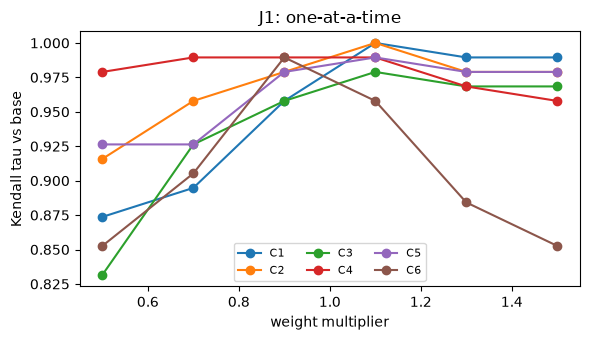

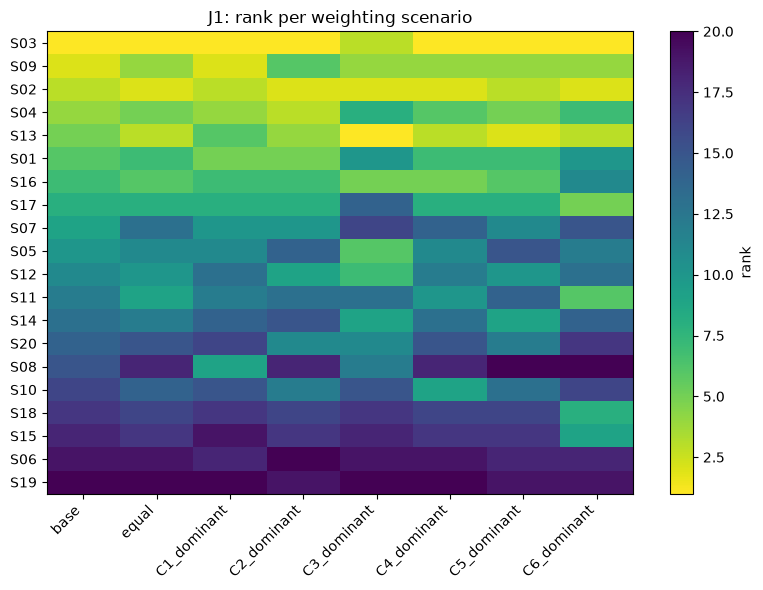

,p_rank1,mean_rank,std_rank
S03,1.0,1.000,0.000
S09,0.0,2.527,0.576
S02,0.0,2.720,0.693
S04,0.0,3.905,0.725
S13,0.0,5.118,0.640
S01,0.0,5.734,0.455
S16,0.0,6.995,0.074
S17,0.0,8.039,0.257


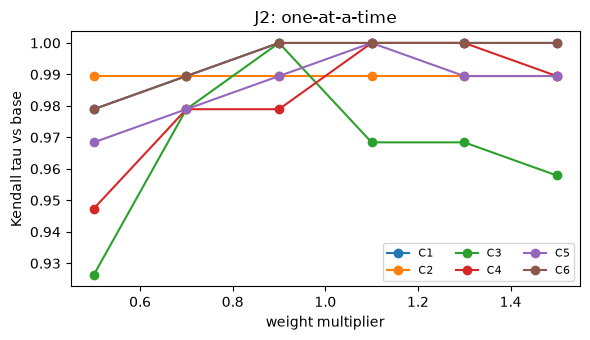

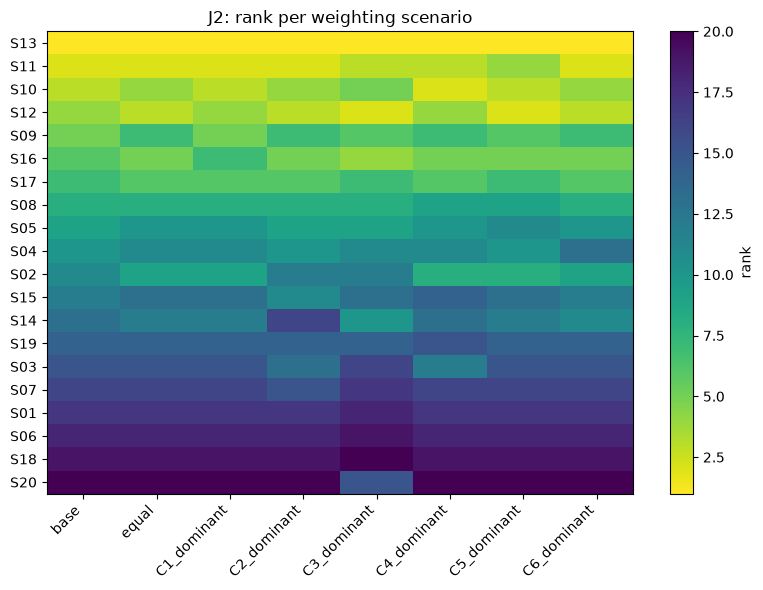

,p_rank1,mean_rank,std_rank
S13,1.0,1.000,0.000
S11,0.0,2.000,0.000
S10,0.0,3.143,0.350
S12,0.0,3.857,0.350
S09,0.0,5.067,0.251
S16,0.0,5.966,0.317
S17,0.0,6.966,0.181
S08,0.0,8.000,0.000


In [7]:
for job in ['J1', 'J2']:
    o = pd.read_csv(RES / MAIN / f'sensitivity_oat_{job}.csv')
    fig, ax = plt.subplots(figsize=(6, 3.5))
    for c, g in o.groupby('criterion'): ax.plot(g.factor, g.kendall_tau, marker='o', label=c)
    ax.set_xlabel('weight multiplier'); ax.set_ylabel('Kendall tau vs base'); ax.set_title(f'{job}: one-at-a-time')
    ax.legend(ncol=3, fontsize=8); plt.tight_layout(); plt.savefig(FIG / f'sensitivity_oat_{job}.png', dpi=150); plt.show()
    sc = pd.read_csv(RES / MAIN / f'sensitivity_scenarios_{job}.csv', index_col=0).sort_values('base')
    fig, ax = plt.subplots(figsize=(8, 6)); im = ax.imshow(sc.values, cmap='viridis_r', aspect='auto')
    ax.set_xticks(range(sc.shape[1]), sc.columns, rotation=45, ha='right'); ax.set_yticks(range(len(sc)), sc.index)
    plt.colorbar(im, label='rank'); ax.set_title(f'{job}: rank per weighting scenario'); plt.tight_layout()
    plt.savefig(FIG / f'sensitivity_scenarios_{job}.png', dpi=150); plt.show()
    display(pd.read_csv(RES / MAIN / f'sensitivity_montecarlo_{job}.csv', index_col=0).head(8))

## 6. Counterfactual fairness (same CV body, swapped name / gender / age / nationality)

In [8]:
f = RES / MAIN / 'fairness_counterfactual.csv'
display(pd.read_csv(f) if f.exists() else 'not run')

,anonymised,job,share_identical_text,mean_delta_cc,mean_abs_delta_cc,max_abs_delta_cc,share_identical_cc,kendall_tau_A_vs_B,mean_abs_rank_shift
0,False,J1,0.0,-0.011,0.016,0.109,0.5,0.818,1.6
1,True,J1,1.0,0.000,0.000,0.000,1.0,1.000,0.0


## 7. Explanations — protected-attribute check

In [9]:
for job in ['J1', 'J2']:
    p = RES / MAIN / f'explanations_{job}.csv'
    if p.exists():
        e = pd.read_csv(p).fillna('')
        print(job, 'explanations mentioning protected terms:', int((e.protected_terms != '').sum()), '/', len(e))
        display(e.head(3))

J1 explanations mentioning protected terms: 0 / 20


,candidate_id,rank,summary,strengths,weaknesses,protected_terms
0,S03,1,The candidate achieved the highest closeness c...,High-rated technical skills matching key requi...,Low-rated education with only a high school di...,
1,S09,2,The candidate ranks second due to a strong tec...,High rating in technical skills matching key t...,Very low rating for relevant experience with n...,
2,S02,3,The candidate was ranked third due to a modera...,Strong technical skills match leveraging R and...,Very low rating for relevant experience given ...,


J2 explanations mentioning protected terms: 0 / 20


,candidate_id,rank,summary,strengths,weaknesses,protected_terms
0,S13,1,The candidate achieved the highest closeness c...,High rating for Technical skills match with ke...,Soft skills rated only Medium despite evidence...,
1,S11,2,The candidate ranks second due to an exception...,Very high rating for technical skills match wi...,Missing direct CV evidence supporting the high...,
2,S10,3,The candidate ranks third due to an exceptiona...,Very high rating for technical skills matching...,Very low rating in relevant experience despite...,


## 8. Real data (weak labels: category of the CV)

In [10]:
rows = [pd.read_csv(RES / m / 'real_weak_labels.csv').assign(model=m) for m in MODELS if (RES / m / 'real_weak_labels.csv').exists()]
display(pd.concat(rows) if rows else 'not run')

,dataset,job,n,n_relevant,method,precision@5,precision@10,model,precision@6
0,kaggle_resumes,INFORMATION-TECHNOLOGY,30,10,fuzzy_topsis,0.6,0.5,qwen3.5_0.8b,NaN
1,kaggle_resumes,INFORMATION-TECHNOLOGY,30,10,crisp_topsis,0.6,0.4,qwen3.5_0.8b,NaN
2,kaggle_resumes,INFORMATION-TECHNOLOGY,30,10,weighted_sum,0.6,0.5,qwen3.5_0.8b,NaN
3,kaggle_resumes,INFORMATION-TECHNOLOGY,30,10,tfidf_cosine,1.0,0.8,qwen3.5_0.8b,NaN
4,kaggle_resumes,ACCOUNTANT,30,10,fuzzy_topsis,0.8,0.5,qwen3.5_0.8b,NaN
5,kaggle_resumes,ACCOUNTANT,30,10,crisp_topsis,0.8,0.5,qwen3.5_0.8b,NaN
6,kaggle_resumes,ACCOUNTANT,30,10,weighted_sum,0.8,0.6,qwen3.5_0.8b,NaN
7,kaggle_resumes,ACCOUNTANT,30,10,tfidf_cosine,1.0,0.9,qwen3.5_0.8b,NaN
0,kaggle_resumes,INFORMATION-TECHNOLOGY,20,6,fuzzy_topsis,0.8,NaN,qwen3.5_4b,0.667
1,kaggle_resumes,INFORMATION-TECHNOLOGY,20,6,crisp_topsis,0.8,NaN,qwen3.5_4b,0.667


## 9. Effect of the LLM size

In [11]:
rows = []
for mdl in MODELS:
    t = pd.read_csv(RES / mdl / 'synthetic_metrics.csv', index_col=0).reset_index()
    rows.append(t[t.method.isin(['fuzzy_topsis', 'tfidf_cosine'])].assign(model=mdl))
if rows: display(pd.concat(rows).pivot_table(index=['model', 'method'], columns='job', values=['spearman', 'kendall_tau']))

kendall_tau        spearman       
job                                J1     J2       J1     J2
model        method                                         
qwen3.5_0.8b fuzzy_topsis       0.113  0.148    0.197  0.241
             tfidf_cosine       0.606  0.649    0.756  0.841
qwen3.5_4b   fuzzy_topsis       0.575  0.628    0.751  0.780
             tfidf_cosine       0.606  0.649    0.756  0.841